# kursinis — ResNet18: CIFAR-10 ir Fashion-MNIST

ResNet18 klasifikavimas su iš anksto ImageNet duomenimis išmokytais svoriais.
Naudojama `SEED=42`, 10 % mokymo duomenų skiriama validavimui, vaizdai
didinami iki 224×224, paketo dydis — 64. Klasifikavimo galva mokoma
3 epochas, visas tinklas derinamas iki 10 epochų su ankstyvuoju stabdymu.

**Paleidimas:** Google Colab → Runtime → Change runtime type → **T4 GPU** →
Run all. Prijunkite Google Drive, kai bus parodytas prisijungimo langas.

**Saugojimas:** `MyDrive/kursinis/duomenys` — duomenų kopijos ir skaidymo
indeksai; `MyDrive/kursinis/cache` — atsisiuntimų ir modelio svorių podėlis;
`MyDrive/kursinis/rezultatai` — grafikai, CSV, JSON ir išmokytų modelių svoriai.
Abu duomenų rinkiniai įkeliami iš Hugging Face. Pakartotinai naudojamos Drive
išsaugotos NumPy kopijos. Pirmą kartą duomenys atsisiunčiami paleidus eksperimentą.

Šaltiniai: [ResNet](https://arxiv.org/abs/1512.03385),
[TorchVision ResNet18](https://docs.pytorch.org/vision/stable/models/generated/torchvision.models.resnet18.html),
[CIFAR-10](https://huggingface.co/datasets/uoft-cs/cifar10),
[Fashion-MNIST](https://huggingface.co/datasets/zalando-datasets/fashion_mnist).


In [1]:
%pip install -q "datasets>=3,<5" "Pillow>=10"

import os
from pathlib import Path
from google.colab import drive

drive.mount('/content/drive')

PROJECT_NAME = 'kursinis'
PROJECT_DIR = Path('/content/drive/MyDrive') / PROJECT_NAME
DATA_DIR = PROJECT_DIR / 'duomenys'
CACHE_DIR = PROJECT_DIR / 'cache'
OUT_DIR = str(PROJECT_DIR / 'rezultatai')
for directory in (DATA_DIR, CACHE_DIR, Path(OUT_DIR)):
    directory.mkdir(parents=True, exist_ok=True)

os.environ['HF_HOME'] = str(CACHE_DIR / 'huggingface')
os.environ['HF_HUB_CACHE'] = str(CACHE_DIR / 'huggingface' / 'hub')
os.environ['HF_DATASETS_CACHE'] = str(CACHE_DIR / 'huggingface' / 'datasets')
print('Projektas:', PROJECT_DIR)
print('Rezultatai:', OUT_DIR)

!nvidia-smi --query-gpu=name,memory.total --format=csv


Mounted at /content/drive
Projektas: /content/drive/MyDrive/kursinis
Rezultatai: /content/drive/MyDrive/kursinis/rezultatai
name, memory.total [MiB]
Tesla T4, 15360 MiB


In [2]:
import time, json, shutil, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch import amp
from torch.utils.data import Dataset, DataLoader
from torchvision import models
from torchvision.models import ResNet18_Weights
from sklearn.metrics import (classification_report, confusion_matrix,
                             precision_recall_fscore_support)
from datasets import load_dataset as hf_load_dataset

SEED = 42
IMG_SIZE = 224
BATCH_SIZE = 64
EPOCHS_HEAD = 3
EPOCHS_FINE = 10
LR_HEAD = 1e-3
LR_FINE = 1e-4
VAL_SPLIT = 0.1
MODEL_NAME = 'ResNet18'
NUM_WORKERS = 2

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Torch:', torch.__version__, '| TorchVision:', __import__('torchvision').__version__, '| Device:', device)
if device.type == 'cpu':
    print('DĖMESIO: aptiktas CPU. Colab pasirinkite T4 GPU, kitaip visas mokymas bus lėtas.')
torch.hub.set_dir(str(CACHE_DIR / 'torch'))
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.benchmark = False
plt.rcParams.update({'figure.dpi': 100, 'savefig.dpi': 200, 'font.size': 11})
MEAN = torch.tensor([0.485,0.456,0.406], dtype=torch.float32).view(1,3,1,1).to(device)
STD  = torch.tensor([0.229,0.224,0.225], dtype=torch.float32).view(1,3,1,1).to(device)


Torch: 2.11.0+cu130 | TorchVision: 0.26.0+cu130 | Device: cuda


## Duomenų įkėlimas ir paruošimas

CIFAR-10: 50 000 mokymo ir 10 000 testavimo vaizdų.
Fashion-MNIST: 60 000 mokymo ir 10 000 testavimo vaizdų.
Validavimui skiriama 10 % mokymo dalies, naudojant `SEED=42`.
Testavimo dalis vertinimui paliekama atskirai.

Pirmą kartą duomenys atsisiunčiami iš Hugging Face ir išsaugomi Drive kaip
`uint8` NumPy masyvai. Kitus kartus naudojami šie failai. Pradinė vaizdų raiška
išlaikoma iki mokymo; Fashion-MNIST vaizdai konvertuojami į tris kanalus.


In [3]:
CLASS_NAMES = {
  'CIFAR-10': ['airplane','automobile','bird','cat','deer','dog','frog','horse','ship','truck'],
  'FashionMNIST': ['T-shirt/top','Trouser','Pullover','Dress','Coat','Sandal','Shirt','Sneaker','Bag','Ankle boot'],
}

DATASET_SOURCES = {
    'CIFAR-10': ('uoft-cs/cifar10', 'img', 50000, (32, 32, 3)),
    'FashionMNIST': ('zalando-datasets/fashion_mnist', 'image', 60000, (28, 28)),
}


def save_npz_atomic(path, **arrays):
    temporary = path.with_suffix('.tmp')
    with temporary.open('wb') as handle:
        np.savez(handle, **arrays)
    os.replace(temporary, path)


def load_raw_arrays(name):
    if name not in DATASET_SOURCES:
        raise ValueError(name)
    repo, image_column, train_count, image_shape = DATASET_SOURCES[name]
    path = DATA_DIR / f'{name}_raw_v1.npz'
    if path.exists():
        print(f'Duomenys iš Drive: {path}')
        with np.load(path, allow_pickle=False) as cached:
            x_tr, y_tr, x_te, y_te = (
                cached[key] for key in ('x_tr', 'y_tr', 'x_te', 'y_te')
            )
    else:
        print(f'Atsisiunčiama iš Hugging Face: {repo}')
        dataset = hf_load_dataset(
            repo, cache_dir=os.environ['HF_DATASETS_CACHE']
        )
        x_tr = np.stack([np.asarray(img, dtype=np.uint8)
                         for img in dataset['train'][image_column]])
        y_tr = np.asarray(dataset['train']['label'], dtype=np.int64)
        x_te = np.stack([np.asarray(img, dtype=np.uint8)
                         for img in dataset['test'][image_column]])
        y_te = np.asarray(dataset['test']['label'], dtype=np.int64)
        save_npz_atomic(path, x_tr=x_tr, y_tr=y_tr, x_te=x_te, y_te=y_te)
        metadata = {
            'source': repo,
            'train_fingerprint': dataset['train']._fingerprint,
            'test_fingerprint': dataset['test']._fingerprint,
        }
        (DATA_DIR / f'{name}_source.json').write_text(
            json.dumps(metadata, ensure_ascii=False, indent=2), encoding='utf-8'
        )
        print(f'Duomenys išsaugoti Drive: {path}')

    if (x_tr.shape != (train_count, *image_shape)
            or x_te.shape != (10000, *image_shape)
            or y_tr.shape != (train_count,) or y_te.shape != (10000,)
            or x_tr.dtype != np.uint8 or x_te.dtype != np.uint8
            or not np.isin(y_tr, np.arange(10)).all()
            or not np.isin(y_te, np.arange(10)).all()):
        raise ValueError(f'Netinkama duomenų forma arba reikšmės: {path}')
    return x_tr, y_tr, x_te, y_te


def load_dataset(name):
    x_tr, y_tr, x_te, y_te = load_raw_arrays(name)
    if name == 'FashionMNIST':
        x_tr = np.repeat(x_tr[..., None], 3, axis=-1)
        x_te = np.repeat(x_te[..., None], 3, axis=-1)
    rng = np.random.default_rng(SEED)
    idx = rng.permutation(len(x_tr))
    n_val = int(len(x_tr) * VAL_SPLIT)
    val_idx, tr_idx = idx[:n_val], idx[n_val:]
    save_npz_atomic(
        DATA_DIR / f'{name}_split_seed{SEED}_val{VAL_SPLIT:g}.npz',
        train_indices=tr_idx, val_indices=val_idx,
    )
    return (x_tr[tr_idx], y_tr[tr_idx]), (x_tr[val_idx], y_tr[val_idx]), (x_te, y_te)

class ImageArrayDataset(Dataset):
    def __init__(self, x, y):
        self.x = torch.from_numpy(np.ascontiguousarray(x.transpose(0,3,1,2)))  # uint8, C,H,W
        self.y = torch.from_numpy(np.asarray(y,dtype=np.int64))
    def __len__(self): return len(self.y)
    def __getitem__(self,i): return self.x[i],self.y[i]

def make_loader(x,y,training):
    return DataLoader(ImageArrayDataset(x,y),batch_size=BATCH_SIZE,shuffle=training,
        num_workers=NUM_WORKERS,pin_memory=(device.type=='cuda'),persistent_workers=NUM_WORKERS>0)

def prepare(x,training=False):
    x = x.to(device,non_blocking=True).float()    # RGB, 0–255
    if training:
        flips = torch.rand(x.size(0),device=device) < 0.5
        x = torch.where(flips[:,None,None,None], torch.flip(x,dims=(-1,)), x)
        theta = torch.eye(2,3,device=device).unsqueeze(0).repeat(x.size(0),1,1)
        # affine_grid koordinates [-1,1] => 0.2 atitinka 10 % vaizdo pločio
        theta[:,0,2] = (torch.rand(x.size(0),device=device)*2-1)*0.2
        theta[:,1,2] = (torch.rand(x.size(0),device=device)*2-1)*0.2
        grid=F.affine_grid(theta,x.size(),align_corners=False)
        x=F.grid_sample(x,grid,mode='bilinear',padding_mode='reflection',align_corners=False)
    x=F.interpolate(x,size=(IMG_SIZE,IMG_SIZE),mode='bilinear',align_corners=False)
    x=x/255.0
    return (x-MEAN)/STD

def plot_samples(x,y,classes,name):
    fig,axs=plt.subplots(2,10,figsize=(15,3.8))
    for ci in range(10):
        indices=np.where(y==ci)[0][:2]
        for r,i in enumerate(indices):
            axs[r,ci].imshow(x[i]);axs[r,ci].axis('off')
            if r==0:axs[r,ci].set_title(classes[ci],fontsize=9)
    fig.suptitle(name+': duomenų pavyzdžiai');fig.tight_layout()
    fig.savefig(f'{OUT_DIR}/{name}_pavyzdziai.png');plt.show();plt.close(fig)

def plot_class_distribution(y_tr,y_val,y_te,classes,name):
    counts=pd.DataFrame({'Mokymo':np.bincount(y_tr,minlength=10),
      'Validavimo':np.bincount(y_val,minlength=10),
      'Testavimo':np.bincount(y_te,minlength=10)},index=classes)
    ax=counts.plot(kind='bar',figsize=(10,4))
    ax.set_ylabel('Vaizdų skaičius');ax.set_title(name+': klasių pasiskirstymas')
    plt.xticks(rotation=45,ha='right');plt.tight_layout()
    plt.savefig(f'{OUT_DIR}/{name}_klasiu_pasiskirstymas.png');plt.show();plt.close()
    counts.to_csv(f'{OUT_DIR}/{name}_klasiu_pasiskirstymas.csv')


## Modelis: ResNet18 su perkeliamuoju mokymusi

Naudojama `torchvision.models.resnet18` realizacija su
`ResNet18_Weights.IMAGENET1K_V1` svoriais. Klasifikavimo sluoksnis keičiamas
į `Dropout(0.2)` ir `Linear(512, 10)`. Pirmiausia mokoma klasifikavimo galva,
tada derinamas visas tinklas. Abiejuose etapuose fiksuojama `BatchNorm`
bėgamoji statistika. RGB vaizdų reikšmės dalijamos iš 255 ir normalizuojamos
pagal `mean=[0.485, 0.456, 0.406]`, `std=[0.229, 0.224, 0.225]`.


In [4]:
def build_model(num_classes=10):
    model=models.resnet18(weights=ResNet18_Weights.IMAGENET1K_V1)
    model.fc=nn.Sequential(nn.Dropout(0.2), nn.Linear(model.fc.in_features,num_classes))
    return model.to(device)

def set_stage(model,head_only):
    for name,p in model.named_parameters():
        p.requires_grad = (name.startswith('fc.') if head_only else True)

def set_train_bn_frozen(model):
    model.train()
    for module in model.modules():
        if isinstance(module,nn.modules.batchnorm._BatchNorm): module.eval()

# Patikrinimas, ar būtent ResNet18 struktūra naudojama:
print('ResNet18 liekamųjų blokų skaičius: [2,2,2,2], klasifikatoriaus įvestis: 512.')


ResNet18 liekamųjų blokų skaičius: [2,2,2,2], klasifikatoriaus įvestis: 512.


## Mokymas, vertinimas ir grafikai

In [5]:
def run_epoch(model,loader,criterion,optimizer=None,scaler=None):
    training=optimizer is not None
    if training:set_train_bn_frozen(model)
    else:model.eval()
    running_loss=0.0;correct=0;count=0
    for images,labels in loader:
        labels=labels.to(device,non_blocking=True)
        x=prepare(images,training=training)
        if training:optimizer.zero_grad(set_to_none=True)
        with torch.set_grad_enabled(training):
            with amp.autocast(device_type=device.type,enabled=device.type=='cuda'):
                logits=model(x)
                loss=criterion(logits,labels)
            if training:
                scaler.scale(loss).backward();scaler.step(optimizer);scaler.update()
        n=labels.size(0);running_loss+=float(loss.item())*n
        correct+=int((logits.argmax(1)==labels).sum().item());count+=n
    return running_loss/count, correct/count

def fit_stage(model,train_loader,val_loader,epochs,lr,head_only):
    set_stage(model,head_only=head_only)
    optimizer=torch.optim.Adam((p for p in model.parameters() if p.requires_grad),lr=lr)
    scaler=amp.GradScaler('cuda',enabled=(device.type=='cuda'))
    criterion=nn.CrossEntropyLoss()
    scheduler=torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer,mode='min',factor=0.5,patience=2)
    hist={'accuracy':[],'val_accuracy':[],'loss':[],'val_loss':[]}
    best_acc=-1.0;best_state=None;bad=0
    for epoch in range(epochs):
        tr_l,tr_a=run_epoch(model,train_loader,criterion,optimizer,scaler)
        va_l,va_a=run_epoch(model,val_loader,criterion)
        hist['accuracy'].append(tr_a);hist['val_accuracy'].append(va_a)
        hist['loss'].append(tr_l);hist['val_loss'].append(va_l)
        print(f'Epocha {epoch+1}/{epochs} | tr loss {tr_l:.4f}, acc {tr_a:.4f} | '
              f'val loss {va_l:.4f}, acc {va_a:.4f} | LR {optimizer.param_groups[0]["lr"]:.2g}')
        scheduler.step(va_l)
        if not head_only:
            if va_a>best_acc+1e-12:
                best_acc=va_a;bad=0
                best_state={k:v.detach().cpu().clone() for k,v in model.state_dict().items()}
            else:
                bad+=1
                if bad>=3:
                    print('EarlyStopping: validavimo tikslumas nepagerėjo 3 epochas.')
                    break
    if best_state is not None:
        model.load_state_dict(best_state) # atkuria geriausią fine-tuning epochą
    return hist

def plot_history(hist,name):
    ep=np.arange(1,len(hist['accuracy'])+1)
    fig,(a1,a2)=plt.subplots(1,2,figsize=(13,4.2))
    for ax,key,title in [(a1,'accuracy','Tikslumas'),(a2,'loss','Nuostolių funkcija')]:
        ax.plot(ep,hist[key],'o-',label='Mokymo')
        ax.plot(ep,hist['val_'+key],'s-',label='Validavimo')
        ax.axvline(EPOCHS_HEAD+0.5,color='gray',ls='--',label='Fine-tuning pradžia')
        ax.set_xlabel('Epocha');ax.set_ylabel(title);ax.set_title(f'{MODEL_NAME}, {name}: {title.lower()}')
        ax.grid(alpha=0.3);ax.legend()
    fig.tight_layout();fig.savefig(f'{OUT_DIR}/{name}_mokymo_kreives.png')
    plt.show();plt.close(fig)

def plot_confusion(y_true,y_pred,classes,name):
    cm=confusion_matrix(y_true,y_pred)
    plt.figure(figsize=(9,7.5))
    sns.heatmap(cm,annot=True,fmt='d',cmap='Blues',xticklabels=classes,yticklabels=classes)
    plt.xlabel('Prognozuota klasė');plt.ylabel('Tikroji klasė')
    plt.title(f'{MODEL_NAME}, {name}: klaidų matrica')
    plt.xticks(rotation=45,ha='right');plt.tight_layout()
    plt.savefig(f'{OUT_DIR}/{name}_klaidu_matrica.png');plt.show();plt.close()

def plot_per_class_f1(report,classes,name):
    f1s=[report[n]['f1-score'] for n in classes]
    plt.figure(figsize=(10,4));bars=plt.bar(classes,f1s)
    plt.bar_label(bars,fmt='%.3f',fontsize=8)
    plt.ylim(0,1);plt.ylabel('F1');plt.title(f'{MODEL_NAME}, {name}: F1 pagal klases')
    plt.xticks(rotation=45,ha='right');plt.tight_layout()
    plt.savefig(f'{OUT_DIR}/{name}_F1_pagal_klases.png');plt.show();plt.close()

def plot_misclassified(x,y_true,y_pred,probs,classes,name,n=12):
    wrong=np.where(y_true!=y_pred)[0]
    if not len(wrong):
        print(name,': klaidingų klasifikacijų nėra.');return
    sel=wrong[np.argsort(-probs[wrong].max(axis=1))][:n]
    cols=min(6,len(sel));rows=int(np.ceil(len(sel)/cols))
    fig,axs=plt.subplots(rows,cols,figsize=(15,2.7*rows),squeeze=False)
    for ax in axs.flat:ax.axis('off')
    for ax,i in zip(axs.flat,sel):
        ax.imshow(x[i]);ax.axis('off')
        ax.set_title(f'Tikra: {classes[y_true[i]]}\nPrognozė: {classes[y_pred[i]]} '
                     f'({probs[i].max():.0%})',fontsize=8)
    fig.suptitle(f'{MODEL_NAME}, {name}: klaidingai klasifikuoti vaizdai')
    fig.tight_layout();fig.savefig(f'{OUT_DIR}/{name}_klaidos.png');plt.show();plt.close(fig)

@torch.no_grad()
def evaluate_model(model,loader):
    model.eval();criterion=nn.CrossEntropyLoss()
    ys=[];probabilities=[];loss_sum=0;total=0
    if device.type=='cuda':torch.cuda.synchronize()
    t0=time.perf_counter()
    for images,y in loader:
        x=prepare(images,False)
        y_dev=y.to(device,non_blocking=True)
        with amp.autocast(device_type=device.type,enabled=device.type=='cuda'):
            logits=model(x);loss=criterion(logits,y_dev)
        probs=logits.float().softmax(1).cpu().numpy()
        probabilities.append(probs);ys.append(y.numpy())
        loss_sum+=float(loss.item())*len(y);total+=len(y)
    if device.type=='cuda':torch.cuda.synchronize()
    infer_batch_ms=(time.perf_counter()-t0)*1000/total
    y_true=np.concatenate(ys);probs=np.concatenate(probabilities)
    return loss_sum/total,y_true,probs,infer_batch_ms

@torch.no_grad()
def single_image_ms(model,image):
    model.eval();x=prepare(image,False)
    for _ in range(10):model(x)
    if device.type=='cuda':torch.cuda.synchronize()
    t0=time.perf_counter()
    for _ in range(100):model(x)
    if device.type=='cuda':torch.cuda.synchronize()
    return 1000*(time.perf_counter()-t0)/100


In [6]:
def run_experiment(name):
    print(f'\n========== {MODEL_NAME} | {name} ==========')
    classes=CLASS_NAMES[name]
    (x_tr,y_tr),(x_val,y_val),(x_te,y_te)=load_dataset(name)
    print(f'Mokymo {len(x_tr)}, validavimo {len(x_val)}, testavimo {len(x_te)}; '
          f'originalus dydis {x_tr.shape[1:]}')
    plot_samples(x_tr,y_tr,classes,name)
    plot_class_distribution(y_tr,y_val,y_te,classes,name)
    train_loader=make_loader(x_tr,y_tr,True)
    val_loader=make_loader(x_val,y_val,False)
    test_loader=make_loader(x_te,y_te,False)
    model=build_model(len(classes))
    all_params=sum(p.numel() for p in model.parameters())
    print(f'Parametrai pakeitus 10 klasių galvą: {all_params:,}')
    start=time.perf_counter()
    print('\n1 etapas: klasifikavimo galvos mokymas')
    h1=fit_stage(model,train_loader,val_loader,EPOCHS_HEAD,LR_HEAD,head_only=True)
    print('\n2 etapas: viso tinklo derinimas')
    h2=fit_stage(model,train_loader,val_loader,EPOCHS_FINE,LR_FINE,head_only=False)
    train_time=time.perf_counter()-start
    hist={k:h1[k]+h2[k] for k in h1}
    pd.DataFrame(hist,index=pd.RangeIndex(1,len(hist['accuracy'])+1,name='Epocha')) \
      .to_csv(f'{OUT_DIR}/{name}_mokymo_istorija.csv')
    plot_history(hist,name)

    test_loss,y_true,probs,batch_ms=evaluate_model(model,test_loader)
    y_pred=probs.argmax(1)
    test_acc=float((y_true==y_pred).mean())
    prec,rec,f1,_=precision_recall_fscore_support(y_true,y_pred,
      labels=np.arange(10),average='macro',zero_division=0)
    print(classification_report(y_true,y_pred,target_names=classes,labels=np.arange(10),digits=4,zero_division=0))
    report=classification_report(y_true,y_pred,target_names=classes,labels=np.arange(10),digits=4,output_dict=True,zero_division=0)
    pd.DataFrame(report).T.round(4).to_csv(f'{OUT_DIR}/{name}_klasifikavimo_ataskaita.csv')
    plot_confusion(y_true,y_pred,classes,name)
    plot_per_class_f1(report,classes,name)
    plot_misclassified(x_te,y_true,y_pred,probs,classes,name)
    single_ms=single_image_ms(model,torch.from_numpy(np.ascontiguousarray(x_te[:1].transpose(0,3,1,2))))
    path=f'{OUT_DIR}/{MODEL_NAME}_{name}.pth'
    torch.save({'state_dict':model.cpu().state_dict(),'model':'resnet18',
       'classes':classes,'img_size':IMG_SIZE,'seed':SEED},path)
    size_mb=os.path.getsize(path)/1024**2
    result={'Modelis':MODEL_NAME,'Duomenų rinkinys':name,'Accuracy':test_acc,
      'Precision (macro)':float(prec),'Recall (macro)':float(rec),'F1 (macro)':float(f1),
      'Testo nuostolis':float(test_loss),'Epochų sk.':len(hist['accuracy']),
      'Mokymo laikas (min)':train_time/60,
      'Inferencija paketu (ms/vaizdui)':batch_ms,
      'Inferencija, 1 vaizdas (ms)':single_ms,
      'Parametrai (mln.)':all_params/1e6,'Modelio dydis (MB)':size_mb}
    with open(f'{OUT_DIR}/{name}_rezultatai.json','w',encoding='utf-8') as f:
        json.dump(result,f,ensure_ascii=False,indent=2)
    print(json.dumps(result,ensure_ascii=False,indent=2))
    if device.type=='cuda':torch.cuda.empty_cache()
    return result


## Eksperimentas 1: CIFAR-10


========== ResNet18 | CIFAR-10 ==========
Atsisiunčiama iš Hugging Face: uoft-cs/cifar10


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:138: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
  warnings.warn(f"\nError while fetching `HF_TOKEN` secret value from your vault: '{str(e)}'.")


README.md:   0%|          | 0.00/5.16k [00:00<?, ?B/s]

plain_text/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  120MB            

plain_text/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

plain_text/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 23.9MB            

plain_text/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/50000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/10000 [00:00<?, ? examples/s]

Duomenys išsaugoti Drive: /content/drive/MyDrive/kursinis/duomenys/CIFAR-10_raw_v1.npz
Mokymo 45000, validavimo 5000, testavimo 10000; originalus dydis (32, 32, 3)


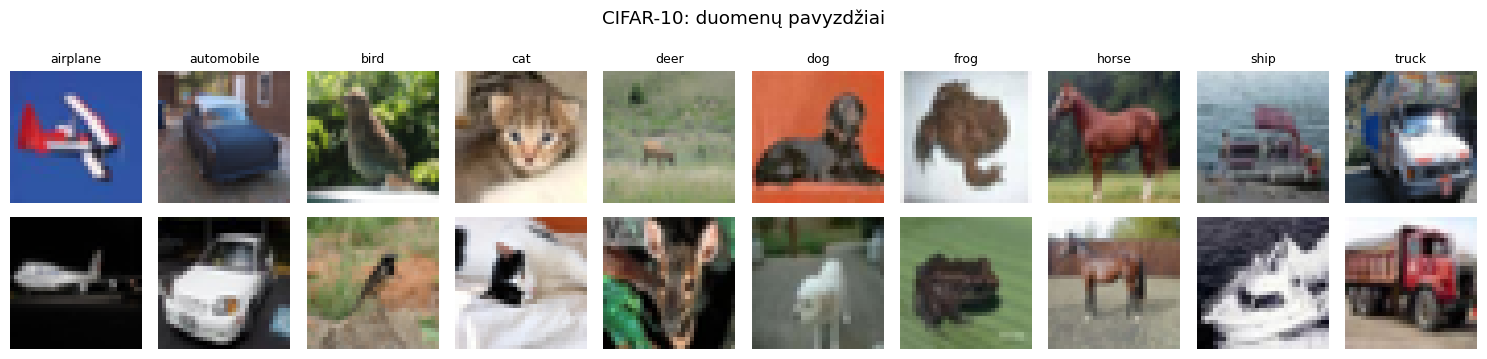

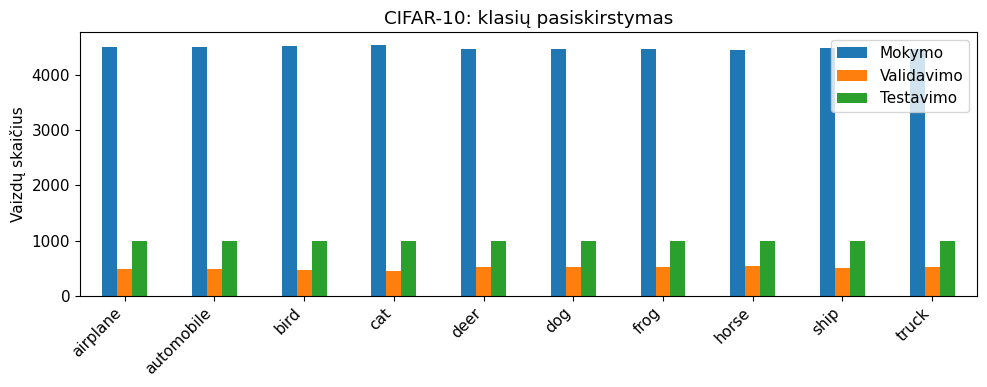

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /content/drive/MyDrive/kursinis/cache/torch/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 121MB/s]


Parametrai pakeitus 10 klasių galvą: 11,181,642

1 etapas: klasifikavimo galvos mokymas
Epocha 1/3 | tr loss 0.8132, acc 0.7299 | val loss 0.4555, acc 0.8522 | LR 0.001
Epocha 2/3 | tr loss 0.6125, acc 0.7863 | val loss 0.4297, acc 0.8546 | LR 0.001
Epocha 3/3 | tr loss 0.5962, acc 0.7899 | val loss 0.4127, acc 0.8628 | LR 0.001

2 etapas: viso tinklo derinimas
Epocha 1/10 | tr loss 0.4091, acc 0.8607 | val loss 0.3218, acc 0.8978 | LR 0.0001
Epocha 2/10 | tr loss 0.2528, acc 0.9143 | val loss 0.2398, acc 0.9204 | LR 0.0001
Epocha 3/10 | tr loss 0.2026, acc 0.9311 | val loss 0.2395, acc 0.9196 | LR 0.0001
Epocha 4/10 | tr loss 0.1662, acc 0.9422 | val loss 0.1914, acc 0.9396 | LR 0.0001
Epocha 5/10 | tr loss 0.1453, acc 0.9498 | val loss 0.2016, acc 0.9376 | LR 0.0001
Epocha 6/10 | tr loss 0.1249, acc 0.9572 | val loss 0.1940, acc 0.9406 | LR 0.0001
Epocha 7/10 | tr loss 0.1137, acc 0.9601 | val loss 0.1984, acc 0.9414 | LR 0.0001
Epocha 8/10 | tr loss 0.0530, acc 0.9814 | val loss 0.1

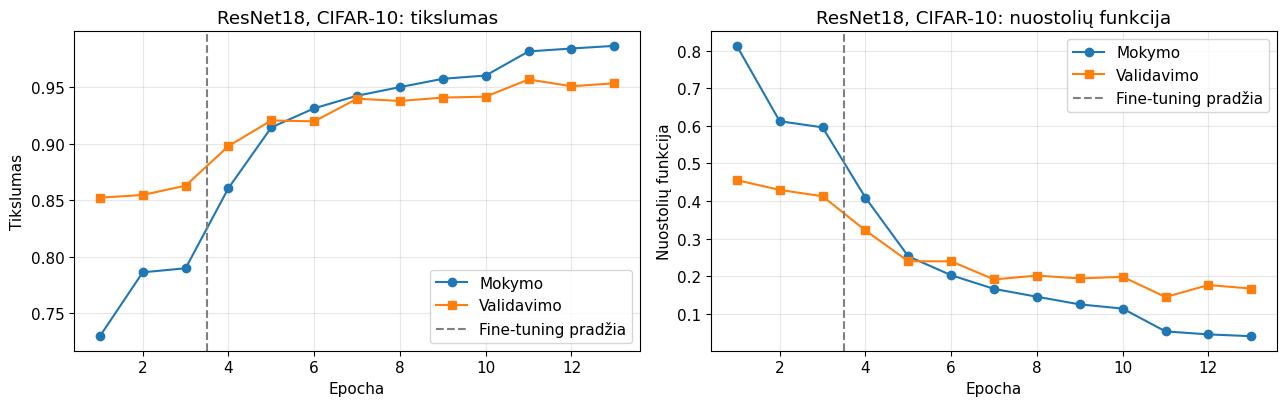

              precision    recall  f1-score   support

    airplane     0.9398    0.9830    0.9609      1000
  automobile     0.9724    0.9850    0.9786      1000
        bird     0.9543    0.9400    0.9471      1000
         cat     0.8921    0.9090    0.9004      1000
        deer     0.9549    0.9520    0.9534      1000
         dog     0.9539    0.8900    0.9208      1000
        frog     0.9553    0.9820    0.9684      1000
       horse     0.9682    0.9740    0.9711      1000
        ship     0.9719    0.9700    0.9710      1000
       truck     0.9846    0.9600    0.9722      1000

    accuracy                         0.9545     10000
   macro avg     0.9547    0.9545    0.9544     10000
weighted avg     0.9547    0.9545    0.9544     10000



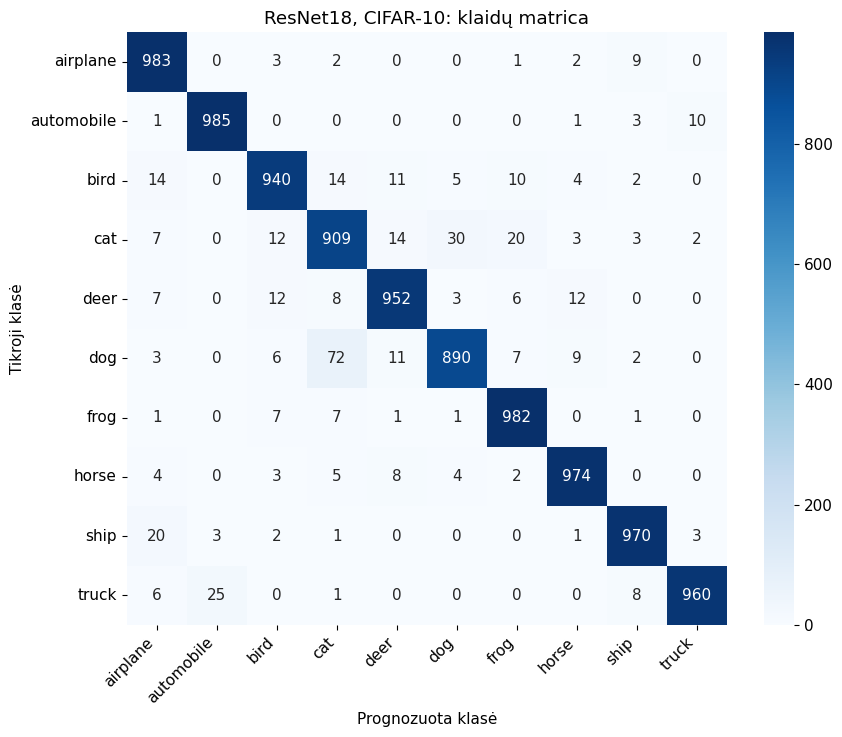

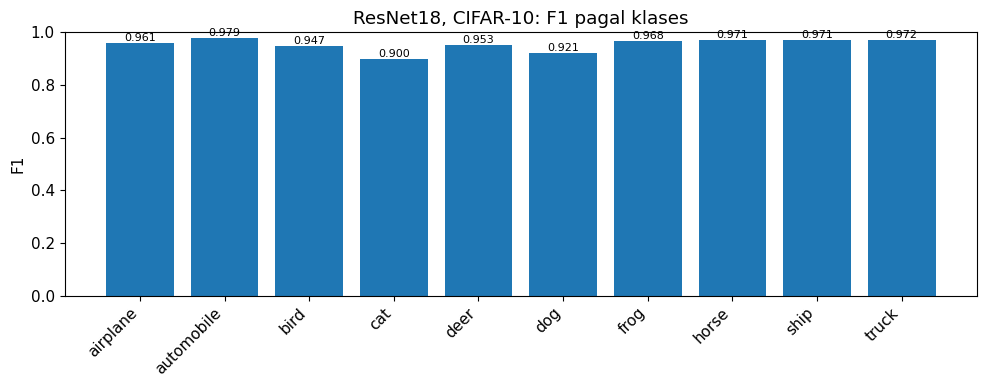

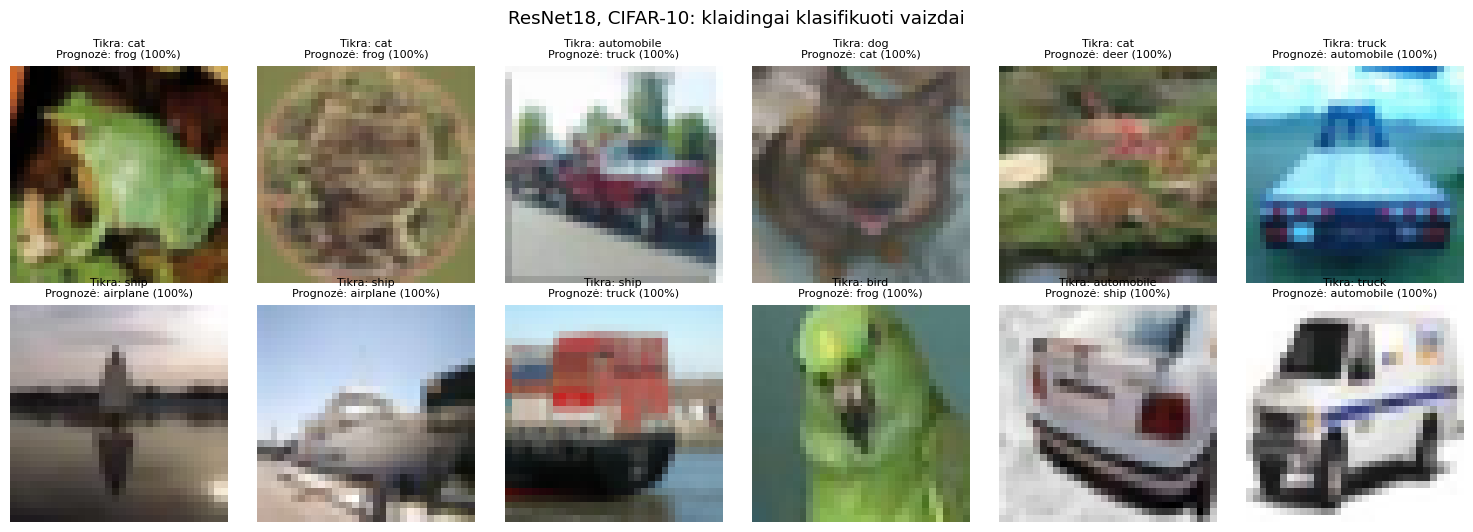

{
  "Modelis": "ResNet18",
  "Duomenų rinkinys": "CIFAR-10",
  "Accuracy": 0.9545,
  "Precision (macro)": 0.9547275385253402,
  "Recall (macro)": 0.9545000000000001,
  "F1 (macro)": 0.954401719445988,
  "Testo nuostolis": 0.15931703877449035,
  "Epochų sk.": 13,
  "Mokymo laikas (min)": 13.489382813266669,
  "Inferencija paketu (ms/vaizdui)": 0.5049377567000193,
  "Inferencija, 1 vaizdas (ms)": 4.140260449999005,
  "Parametrai (mln.)": 11.181642,
  "Modelio dydis (MB)": 42.73005199432373
}


In [7]:
res_cifar = run_experiment("CIFAR-10")

## Eksperimentas 2: Fashion-MNIST


========== ResNet18 | FashionMNIST ==========
Atsisiunčiama iš Hugging Face: zalando-datasets/fashion_mnist


README.md:   0%|          | 0.00/9.02k [00:00<?, ?B/s]

fashion_mnist/train-00000-of-00001.parqu(…): reconstructing file:   0%|          |  0.00B / 30.9MB            

fashion_mnist/train-00000-of-00001.parqu(…): downloading bytes:           |  0.00B            

fashion_mnist/test-00000-of-00001.parque(…): reconstructing file:   0%|          |  0.00B / 5.18MB            

fashion_mnist/test-00000-of-00001.parque(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/60000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/10000 [00:00<?, ? examples/s]

Duomenys išsaugoti Drive: /content/drive/MyDrive/kursinis/duomenys/FashionMNIST_raw_v1.npz
Mokymo 54000, validavimo 6000, testavimo 10000; originalus dydis (28, 28, 3)


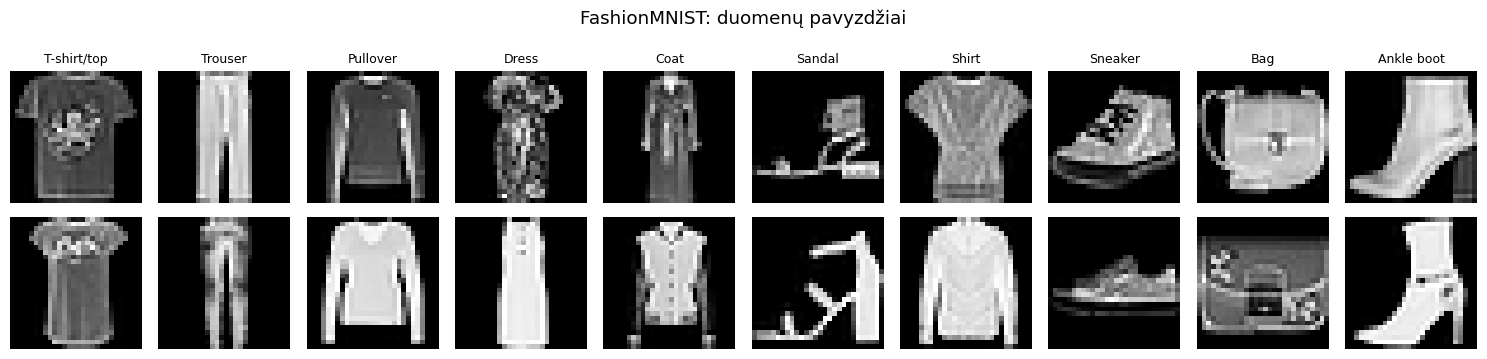

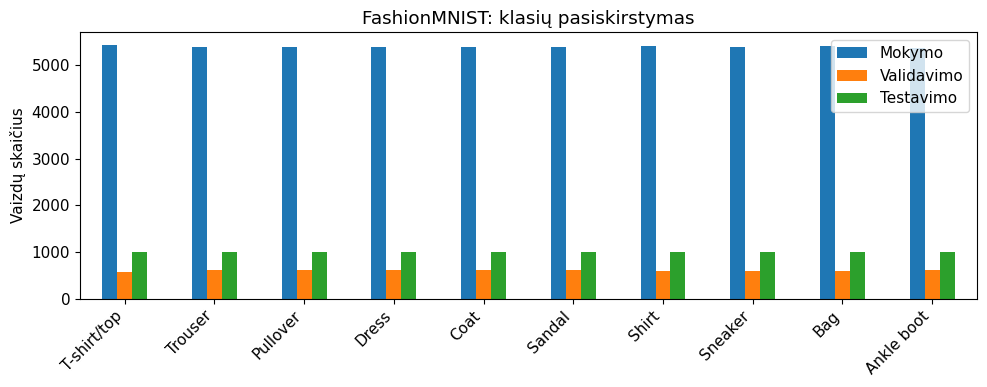

Parametrai pakeitus 10 klasių galvą: 11,181,642

1 etapas: klasifikavimo galvos mokymas
Epocha 1/3 | tr loss 0.6068, acc 0.7971 | val loss 0.4173, acc 0.8412 | LR 0.001
Epocha 2/3 | tr loss 0.4551, acc 0.8356 | val loss 0.3850, acc 0.8553 | LR 0.001
Epocha 3/3 | tr loss 0.4397, acc 0.8420 | val loss 0.3864, acc 0.8552 | LR 0.001

2 etapas: viso tinklo derinimas
Epocha 1/10 | tr loss 0.3244, acc 0.8821 | val loss 0.2728, acc 0.8963 | LR 0.0001
Epocha 2/10 | tr loss 0.2327, acc 0.9146 | val loss 0.2161, acc 0.9203 | LR 0.0001
Epocha 3/10 | tr loss 0.2023, acc 0.9257 | val loss 0.1826, acc 0.9325 | LR 0.0001
Epocha 4/10 | tr loss 0.1818, acc 0.9340 | val loss 0.1670, acc 0.9355 | LR 0.0001
Epocha 5/10 | tr loss 0.1634, acc 0.9401 | val loss 0.1946, acc 0.9302 | LR 0.0001
Epocha 6/10 | tr loss 0.1531, acc 0.9440 | val loss 0.1712, acc 0.9357 | LR 0.0001
Epocha 7/10 | tr loss 0.1433, acc 0.9471 | val loss 0.1599, acc 0.9442 | LR 0.0001
Epocha 8/10 | tr loss 0.1328, acc 0.9515 | val loss 0.1

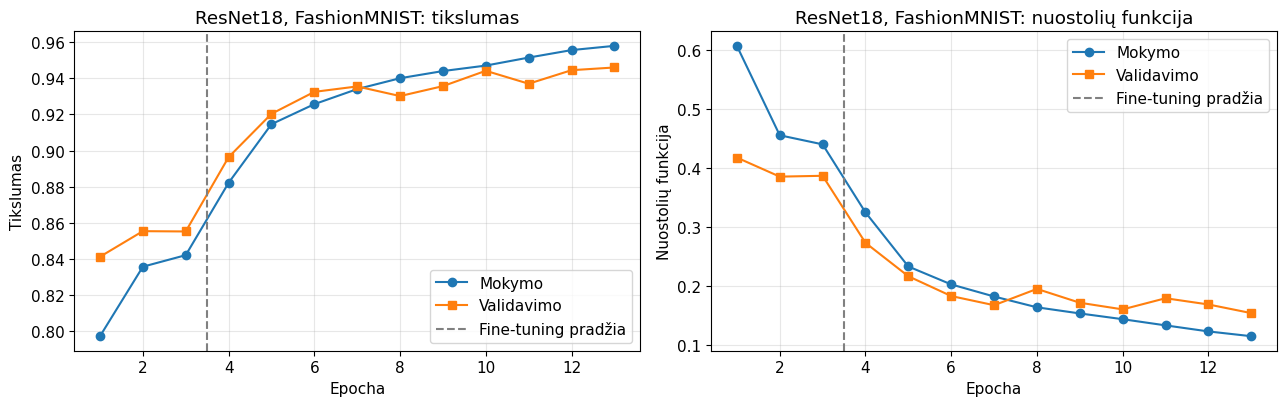

              precision    recall  f1-score   support

 T-shirt/top     0.9020    0.8930    0.8975      1000
     Trouser     0.9980    0.9830    0.9904      1000
    Pullover     0.8912    0.9340    0.9121      1000
       Dress     0.9535    0.9230    0.9380      1000
        Coat     0.9416    0.9030    0.9219      1000
      Sandal     0.9910    0.9910    0.9910      1000
       Shirt     0.8146    0.8570    0.8353      1000
     Sneaker     0.9620    0.9870    0.9743      1000
         Bag     0.9950    0.9940    0.9945      1000
  Ankle boot     0.9866    0.9600    0.9731      1000

    accuracy                         0.9425     10000
   macro avg     0.9436    0.9425    0.9428     10000
weighted avg     0.9436    0.9425    0.9428     10000



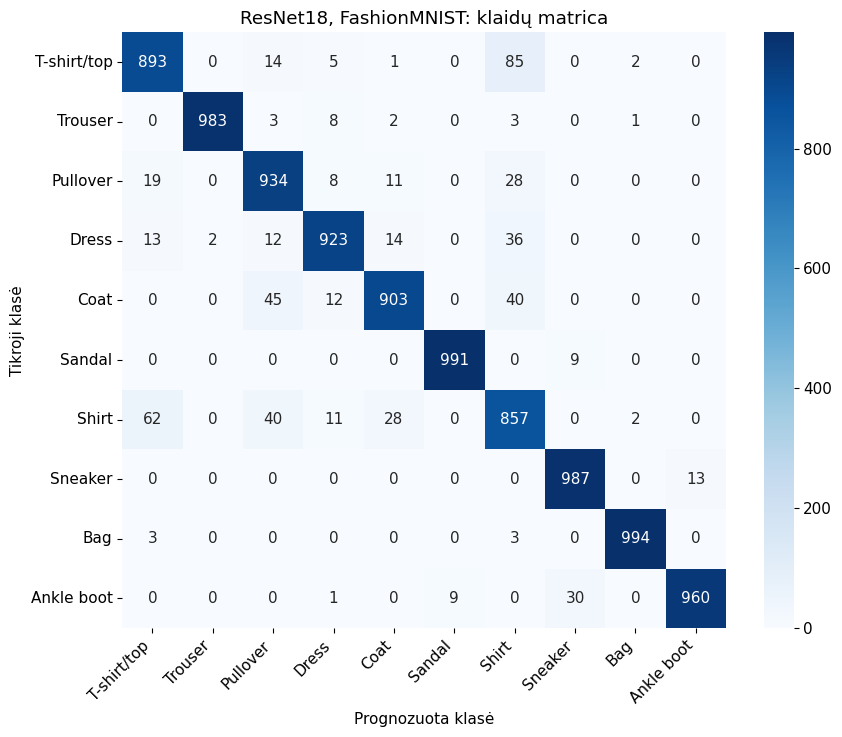

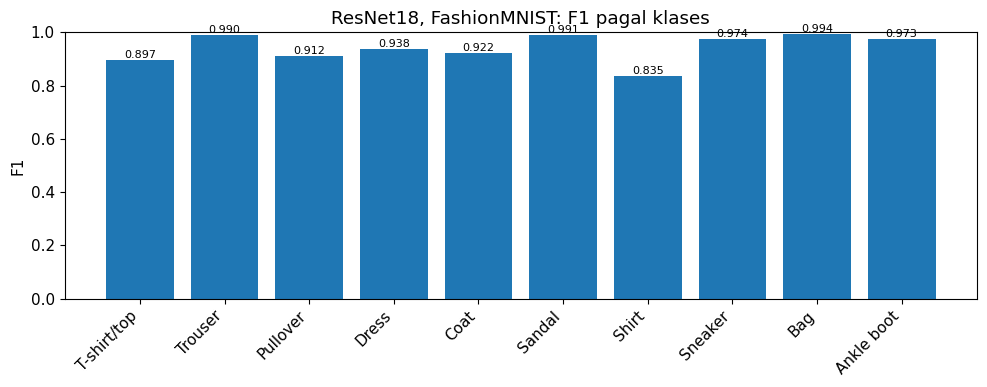

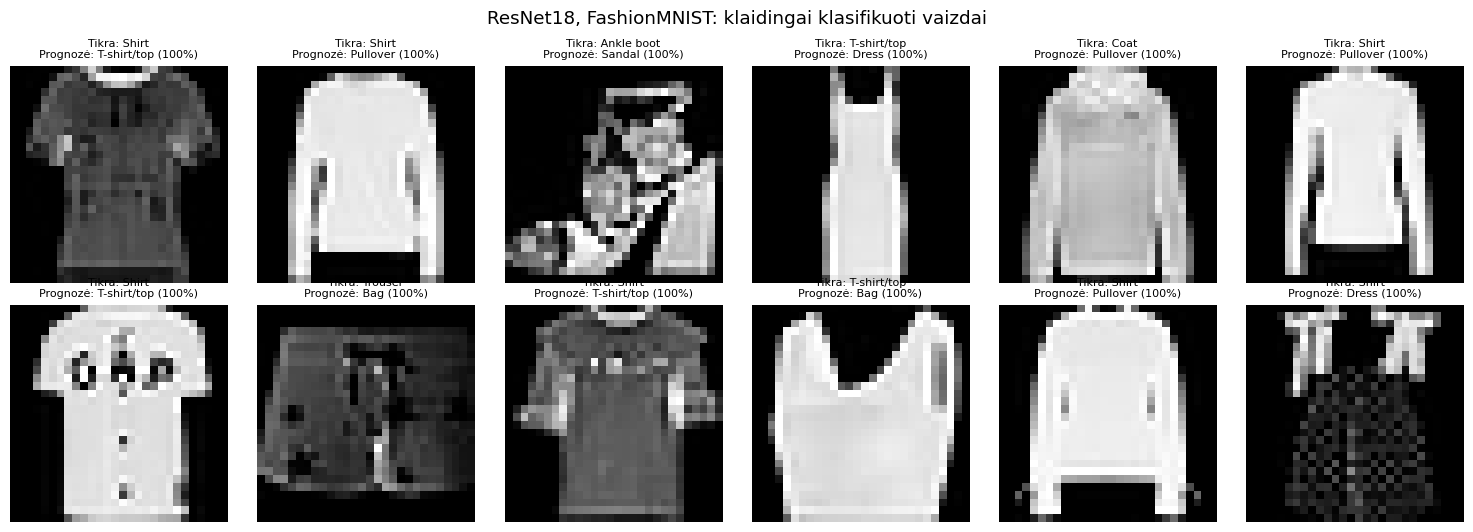

{
  "Modelis": "ResNet18",
  "Duomenų rinkinys": "FashionMNIST",
  "Accuracy": 0.9425,
  "Precision (macro)": 0.9435590697702564,
  "Recall (macro)": 0.9425000000000001,
  "F1 (macro)": 0.9428182998246832,
  "Testo nuostolis": 0.1709607719182968,
  "Epochų sk.": 13,
  "Mokymo laikas (min)": 16.033621366883335,
  "Inferencija paketu (ms/vaizdui)": 0.49393684860001486,
  "Inferencija, 1 vaizdas (ms)": 4.253254380000726,
  "Parametrai (mln.)": 11.181642,
  "Modelio dydis (MB)": 42.73054027557373
}


In [8]:
res_fashion = run_experiment("FashionMNIST")

## Suvestinė lentelė ir metrikos

Abiejų duomenų rinkinių tikslumas, macro precision, recall, F1, mokymo laikas,
inferencijos trukmė ir modelio dydis išsaugomi bendroje CSV lentelėje.


,0,1
Modelis,ResNet18,ResNet18
Duomenų rinkinys,CIFAR-10,FashionMNIST
Accuracy,0.9545,0.9425
Precision (macro),0.9547,0.9436
Recall (macro),0.9545,0.9425
F1 (macro),0.9544,0.9428
Testo nuostolis,0.1593,0.171
Epochų sk.,13,13
Mokymo laikas (min),13.4894,16.0336
Inferencija paketu (ms/vaizdui),0.5049,0.4939


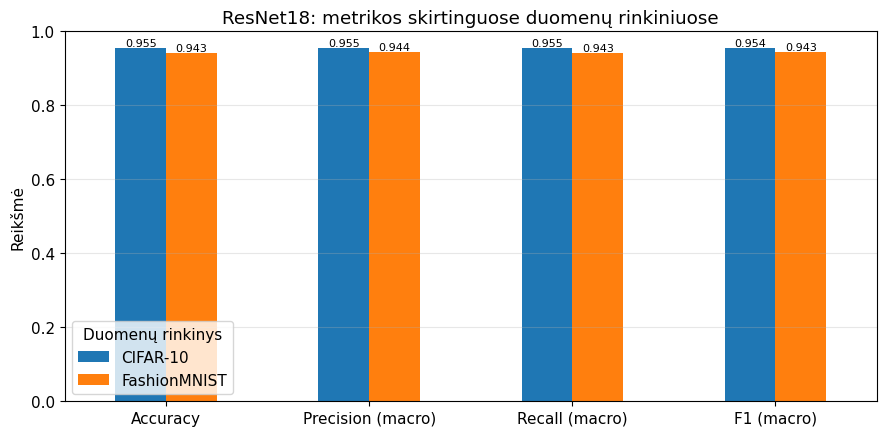

In [9]:
summary=pd.DataFrame([res_cifar,res_fashion]).round(4)
summary.to_csv(f'{OUT_DIR}/{MODEL_NAME}_suvestine.csv',index=False)
display(summary.T)
metrics=['Accuracy','Precision (macro)','Recall (macro)','F1 (macro)']
ax=summary.set_index('Duomenų rinkinys')[metrics].T.plot(kind='bar',figsize=(9,4.5))
for cont in ax.containers:ax.bar_label(cont,fmt='%.3f',fontsize=8)
plt.ylim(0,1);plt.ylabel('Reikšmė');plt.xticks(rotation=0)
plt.title(f'{MODEL_NAME}: metrikos skirtinguose duomenų rinkiniuose')
plt.grid(axis='y',alpha=0.3);plt.tight_layout()
plt.savefig(f'{OUT_DIR}/{MODEL_NAME}_metriku_palyginimas.png');plt.show();plt.close()


## Rezultatų archyvas Drive

Grafikai, metrikos ir modelių svoriai saugomi `MyDrive/kursinis/rezultatai`.
Šis langelis papildomai sukuria rezultatų ZIP archyvą projekto aplanke.


In [10]:
archive = shutil.make_archive(str(PROJECT_DIR / 'ResNet18_rezultatai'), 'zip', OUT_DIR)
print('Rezultatai išsaugoti:', OUT_DIR)
print('ZIP archyvas:', archive)


Rezultatai išsaugoti: /content/drive/MyDrive/kursinis/rezultatai
ZIP archyvas: /content/drive/MyDrive/kursinis/ResNet18_rezultatai.zip
